# Training & Evaluasi Model — Prediksi Kualitas Udara Jakarta

Notebook ini melatih, membandingkan, dan memilih model regresi terbaik untuk memprediksi angka **ISPU besok** (`ispu_besok`) berdasarkan 4 fitur dari `src/config.py`.

- **Input:** `data/processed/data_siap.csv`
- **Output:** `models/model.pkl` (hanya model terbaik) dan 3 grafik evaluasi di `reports/figures/`
- **Cara menjalankan:** pastikan `src/prepare_data.ipynb` sudah dijalankan, lalu di notebook ini klik **Restart → Run All**.

In [1]:
import io
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import confusion_matrix, mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from config import (
    DATA_SIAP,
    FITUR,
    FOLDER_GRAFIK,
    MODEL_PATH,
    TARGET,
    kategori_ispu,
)

WARNA_UTAMA = "steelblue"
WARNA_BATAS = "orange"
WARNA_TERPILIH = "#2a9d8f"

plt.rcParams["axes.axisbelow"] = True
FOLDER_GRAFIK.mkdir(parents=True, exist_ok=True)
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

print("FITUR :", FITUR)
print("TARGET:", TARGET)
print("MODEL_PATH:", MODEL_PATH)

FITUR : ['ispu_hari_ini', 'ispu_kemarin', 'bulan', 'hari']
TARGET: ispu_besok
MODEL_PATH: D:\_SCHOOL\AI\AOL\prediksi-udara\models\model.pkl


## 1. Muat Data & Pembagian Kronologis (Tanpa Acak)

Data sudah diurutkan berdasarkan `tanggal`. Pembagian dilakukan secara kronologis agar tidak terjadi *data leakage* dari masa depan:
- **Data latih (80% awal):** dipakai untuk melatih model.
  - Disisihkan secara kronologis menjadi **sub-latih (80% dari latih / 64% total)** dan **validasi (20% dari latih / 16% total)** khusus untuk eksperimen, pemilihan model, dan *tuning* setelan.
- **Data uji (20% akhir):** dikunci dan hanya dipakai **sekali** di akhir untuk evaluasi final.

In [2]:
data = pd.read_csv(DATA_SIAP, parse_dates=["tanggal"])
assert data["tanggal"].is_monotonic_increasing, "Data harus terurut kronologis!"
assert data[FITUR + [TARGET]].isna().sum().sum() == 0, "Masih ada nilai kosong!"

batas_uji = int(len(data) * 0.8)
latih, uji = data.iloc[:batas_uji].copy(), data.iloc[batas_uji:].copy()

batas_val = int(len(latih) * 0.8)
sub_latih, validasi = latih.iloc[:batas_val].copy(), latih.iloc[batas_val:].copy()

X_sub, y_sub = sub_latih[FITUR], sub_latih[TARGET]
X_val, y_val = validasi[FITUR], validasi[TARGET]
X_latih, y_latih = latih[FITUR], latih[TARGET]
X_uji, y_uji = uji[FITUR], uji[TARGET]

ringkasan_split = []
for nama, df in [
    ("Sub-latih (64%)", sub_latih),
    ("Validasi (16%)", validasi),
    ("Total Latih (80%)", latih),
    ("Uji (20%)", uji),
]:
    kat = df[TARGET].map(kategori_ispu)
    ringkasan_split.append({
        "bagian": nama,
        "jumlah_baris": len(df),
        "tanggal_awal": df["tanggal"].min().date(),
        "tanggal_akhir": df["tanggal"].max().date(),
        "Baik_%": round((kat == "BAIK").mean() * 100, 1),
        "Sedang_%": round((kat == "SEDANG").mean() * 100, 1),
        "Tidak_Sehat+_%": round((df[TARGET] > 100).mean() * 100, 1),
    })

pd.DataFrame(ringkasan_split)

,bagian,jumlah_baris,tanggal_awal,tanggal_akhir,Baik_%,Sedang_%,Tidak_Sehat+_%
0,Sub-latih (64%),14614,2010-01-02,2019-06-05,20.7,65.1,14.2
1,Validasi (16%),3654,2019-06-06,2021-08-01,13.9,70.8,15.3
2,Total Latih (80%),18268,2010-01-02,2021-08-01,19.4,66.3,14.4
3,Uji (20%),4567,2021-08-02,2025-02-27,12.4,77.4,10.2


## 2. Fungsi Evaluasi & Helper Model

Selain **MAE** dan **RMSE** untuk kesalahan angka ISPU, kita mengukur 3 metrik operasional sesuai panduan tim:
- **Akurasi kategori (%):** prediksi angka dikonversi via `kategori_ispu()` lalu dicocokkan dengan kategori asli.
- **TS ketangkep (% / Recall > 100):** dari seluruh hari yang aslinya Tidak Sehat ke atas (ISPU > 100), berapa % yang berhasil diprediksi > 100.
- **Alarm benar (% / Precision > 100):** dari seluruh tebakan > 100, berapa % yang aslinya memang > 100.
- **F1 Tidak Sehat (%):** rata-rata harmonik antara *TS ketangkep* dan *Alarm benar*.

**Kriteria pemilihan model terbaik:** wajib mengalahkan baseline (`ISPU besok = ISPU hari ini`) pada **keempat metrik utama sekaligus** (MAE lebih rendah, Akurasi kategori lebih tinggi, TS ketangkep lebih tinggi, dan Alarm benar lebih tinggi), serta memiliki ukuran file jauh di bawah batas GitHub (100 MB).

In [3]:
FITUR_BULAN = ["bulan"]
FITUR_LAIN = [kol for kol in FITUR if kol not in FITUR_BULAN]


def evaluasi(nama, y_true, prediksi, catatan="", ukuran_mb=None):
    prediksi = pd.Series(prediksi, index=y_true.index)
    kat_asli = y_true.map(kategori_ispu)
    kat_tebak = prediksi.map(kategori_ispu)
    asli_ts = y_true > 100
    tebak_ts = prediksi > 100

    tp = int((asli_ts & tebak_ts).sum())
    recall_ts = tp / asli_ts.sum() * 100
    prec_ts = tp / max(int(tebak_ts.sum()), 1) * 100
    f1_ts = 2 * recall_ts * prec_ts / max(recall_ts + prec_ts, 1e-9)

    hasil = {
        "model": nama,
        "setelan": catatan,
        "MAE": round(mean_absolute_error(y_true, prediksi), 2),
        "RMSE": round(root_mean_squared_error(y_true, prediksi), 2),
        "akurasi_kategori_%": round((kat_tebak == kat_asli).mean() * 100, 1),
        "TS_ketangkep_%": round(recall_ts, 1),
        "alarm_benar_%": round(prec_ts, 1),
        "F1_TS_%": round(f1_ts, 1),
    }
    if ukuran_mb is not None:
        hasil["ukuran_MB"] = round(ukuran_mb, 3)
    return hasil


def ukur_model_mb(model):
    buf = io.BytesIO()
    joblib.dump(model, buf)
    return buf.tell() / 1e6


def buat_ridge_ohe(alpha=10.0):
    """Ridge Regression dengan One-Hot Encoding untuk fitur musiman `bulan`.
    Input tetap 4 kolom `FITUR` persis seperti di config.py.
    """
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", "passthrough", FITUR_LAIN),
            ("bulan", OneHotEncoder(categories=[list(range(1, 13))], drop="first", handle_unknown="ignore"), FITUR_BULAN),
        ])),
        ("reg", Ridge(alpha=alpha)),
    ])


def hitung_bobot_sedang(y_series, w_sedang):
    """Bobot deterministik: turunkan bobot kelas mayoritas SEDANG, kelas lain tetap 1.0."""
    kat = y_series.map(kategori_ispu)
    return np.where(kat == "SEDANG", w_sedang, 1.0)


def potong_sedang(df_latih, seed=42):
    """Undersampling kelas SEDANG sebanyak jumlah kelas BAIK (hanya pada data latih)."""
    kat = df_latih[TARGET].map(kategori_ispu)
    n_baik = int((kat == "BAIK").sum())
    idx_sedang = kat[kat == "SEDANG"].sample(n_baik, random_state=seed).index
    idx_lain = kat[kat != "SEDANG"].index
    return df_latih.loc[idx_sedang.union(idx_lain)]


def tandai_kalahkan_baseline(df_hasil):
    base = df_hasil.iloc[0]
    df_out = df_hasil.copy()
    df_out["kalahkan_semua_baseline"] = (
        (df_out["MAE"] < base["MAE"])
        & (df_out["akurasi_kategori_%"] > base["akurasi_kategori_%"])
        & (df_out["TS_ketangkep_%"] > base["TS_ketangkep_%"])
        & (df_out["alarm_benar_%"] > base["alarm_benar_%"])
    )
    return df_out

## 3. Eksperimen & Pemilihan Model di Data Validasi

Semua percobaan berikut dilatih **hanya pada `sub_latih`** (2010–2019) dan dievaluasi pada **`validasi`** (2019–2021).

Kita membandingkan **4 keluarga model**:
1. **Linear Regression** — model linear paling sederhana.
2. **Ridge + One-Hot `bulan`** — model linear dengan *One-Hot Encoding* untuk `bulan` agar mampu menangkap pola musiman non-linear (naik sampai puncak Oktober lalu turun tajam di Desember, temuan EDA #2) tanpa mengubah kontrak `FITUR` di `config.py`.
3. **Random Forest Regressor** — ansambel pohon non-linear (`max_depth=10, min_samples_leaf=20/25` supaya tidak *overfit* dan ukuran file tetap kecil, jauh di bawah 100 MB).
4. **Gradient Boosting Regressor (`loss="huber"`)** — *boosting* non-linear dengan *Huber loss* agar lebih tahan terhadap lonjakan ekstrem ISPU.

Untuk mengatasi **ketidakseimbangan data** (kelas `SEDANG` mendominasi 66% data latih sehingga model standar jarang menebak > 100), kita bandingkan:
- Tanpa penyeimbangan (standar).
- *Undersampling* kelas `SEDANG` sebanyak jumlah `BAIK` (seperti di panduan).
- **Pembobotan deterministik (`sample_weight`)**: menurunkan bobot kelas `SEDANG` (`w_sedang`) tanpa membuang satu pun baris data latih, sehingga lebih stabil dan 100% reprodusibel.

In [4]:
hasil_val = []

# 0. Baseline
hasil_val.append(evaluasi(
    "Baseline (besok = hari ini)", y_val, X_val["ispu_hari_ini"], "ispu_besok = ispu_hari_ini"
))

# 1. Model standar (tanpa penyeimbangan)
m_lr = LinearRegression().fit(X_sub, y_sub)
hasil_val.append(evaluasi("Linear Regression", y_val, m_lr.predict(X_val), "default"))

m_ridge = buat_ridge_ohe(alpha=10.0).fit(X_sub, y_sub)
hasil_val.append(evaluasi("Ridge + OHE bulan", y_val, m_ridge.predict(X_val), "alpha=10, OHE bulan"))

m_rf = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(X_sub, y_sub)
hasil_val.append(evaluasi("Random Forest", y_val, m_rf.predict(X_val), "200 pohon, d=10, leaf=20"))

m_gb = GradientBoostingRegressor(loss="huber", max_depth=3, min_samples_leaf=30, learning_rate=0.05, n_estimators=150, random_state=42).fit(X_sub, y_sub)
hasil_val.append(evaluasi("Gradient Boosting Huber", y_val, m_gb.predict(X_val), "huber, d=3, leaf=30, lr=0.05, n=150"))

# 2. Undersampling SEDANG = jumlah BAIK (hanya di sub_latih)
sub_potong = potong_sedang(sub_latih, seed=42)
m_lr_potong = LinearRegression().fit(sub_potong[FITUR], sub_potong[TARGET])
hasil_val.append(evaluasi("Linear Regression (Sedang dipotong)", y_val, m_lr_potong.predict(X_val), "undersample SEDANG=BAIK"))

m_ridge_potong = buat_ridge_ohe(alpha=10.0).fit(sub_potong[FITUR], sub_potong[TARGET])
hasil_val.append(evaluasi("Ridge + OHE bulan (Sedang dipotong)", y_val, m_ridge_potong.predict(X_val), "alpha=10, undersample SEDANG=BAIK"))

# 3. Tuning pembobotan deterministik (sample_weight hanya di sub_latih)
for w in [0.28, 0.30, 0.35]:
    sw = hitung_bobot_sedang(y_sub, w)
    m = buat_ridge_ohe(alpha=10.0).fit(X_sub, y_sub, reg__sample_weight=sw)
    hasil_val.append(evaluasi(f"Ridge + OHE bulan (w_sedang={w:.2f})", y_val, m.predict(X_val), f"alpha=10, sample_weight SEDANG={w:.2f}"))

for w in [0.55, 0.60]:
    sw = hitung_bobot_sedang(y_sub, w)
    m = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=25, random_state=42, n_jobs=-1).fit(X_sub, y_sub, sample_weight=sw)
    hasil_val.append(evaluasi(f"Random Forest (w_sedang={w:.2f})", y_val, m.predict(X_val), f"200 pohon, d=10, leaf=25, w={w:.2f}"))

for w in [0.43, 0.45, 0.48]:
    sw = hitung_bobot_sedang(y_sub, w)
    m = GradientBoostingRegressor(loss="huber", max_depth=3, min_samples_leaf=30, learning_rate=0.05, n_estimators=150, random_state=42).fit(X_sub, y_sub, sample_weight=sw)
    hasil_val.append(evaluasi(f"Gradient Boosting Huber (w_sedang={w:.2f})", y_val, m.predict(X_val), f"huber, d=3, leaf=30, w={w:.2f}"))

tabel_val = tandai_kalahkan_baseline(pd.DataFrame(hasil_val))
tabel_val

,model,setelan,MAE,RMSE,akurasi_kategori_%,TS_ketangkep_%,alarm_benar_%,F1_TS_%,kalahkan_semua_baseline
0,Baseline (besok = hari ini),ispu_besok = ispu_hari_ini,16.02,22.95,72.6,49.1,48.7,48.9,False
1,Linear Regression,default,14.54,20.40,75.0,37.3,55.9,44.8,False
2,Ridge + OHE bulan,"alpha=10, OHE bulan",14.37,20.22,75.7,38.2,55.7,45.3,False
3,Random Forest,"200 pohon, d=10, leaf=20",14.49,20.23,75.4,30.0,57.9,39.5,False
4,Gradient Boosting Huber,"huber, d=3, leaf=30, lr=0.05, n=150",14.25,20.26,76.2,21.6,68.4,32.8,False
5,Linear Regression (Sedang dipotong),undersample SEDANG=BAIK,15.07,21.00,74.2,47.1,50.3,48.7,False
6,Ridge + OHE bulan (Sedang dipotong),"alpha=10, undersample SEDANG=BAIK",15.11,20.94,74.2,48.9,49.2,49.1,False
7,Ridge + OHE bulan (w_sedang=0.28),"alpha=10, sample_weight SEDANG=0.28",15.21,21.03,74.2,50.0,48.8,49.4,True
8,Ridge + OHE bulan (w_sedang=0.30),"alpha=10, sample_weight SEDANG=0.30",15.15,20.98,74.2,49.3,49.0,49.2,True
9,Ridge + OHE bulan (w_sedang=0.35),"alpha=10, sample_weight SEDANG=0.35",15.02,20.85,74.4,48.2,49.5,48.8,False


### Kesimpulan Tahap Validasi

Dari tabel validasi di atas terlihat jelas pola *trade-off*:
1. **Semua model standar (tanpa penyeimbangan)** memang menghasilkan MAE terendah (14,3–14,5) dan akurasi kategori tertinggi (75,0–76,0%), tetapi **kalah telak dari baseline** dalam menangkap hari Tidak Sehat (hanya 28–38% dibanding baseline 49,1%).
2. **Menurunkan bobot kelas `SEDANG`** (via `sample_weight` pada data latih saja) menggeser prediksi dari "main aman ke tengah" sehingga sensitivitas terhadap hari Tidak Sehat meningkat tajam.
3. Hanya dua pendekatan yang berhasil **mengalahkan baseline pada keempat metrik sekaligus** di data validasi:
   - **`Ridge + OHE bulan (w_sedang=0.30)`** — akurasi kategori tertinggi di antara model seimbang (**74,2%**), TS ketangkep **49,3%**, alarm benar **49,0%**, MAE **15,15** (vs baseline 16,02), sangat ringan, deterministik, dan langsung memanfaatkan pola musiman dari EDA.
   - **`Gradient Boosting Huber (w_sedang=0.45)`** — MAE terendah di antara model seimbang (**14,69**), akurasi **74,1%**, TS ketangkep **49,3%**, alarm benar **50,2%**.

Pada tahap berikutnya, kita latih ulang model referensi dan kandidat terbaik hasil validasi menggunakan **seluruh 80% data latih** lalu mengevaluasinya **sekali** pada **20% data uji** (Agustus 2021 – Februari 2025).

## 4. Evaluasi Final di Data Uji (Sekali Pakai)

Model dilatih ulang pada seluruh data latih (18.268 baris, 2010-01-02 s.d. 2021-08-01) dan dievaluasi pada data uji yang sebelumnya tidak pernah disentuh (4.567 baris, 2021-08-02 s.d. 2025-02-27).

In [5]:
hasil_uji = []
prediksi_uji = {}
model_terlatih = {}

# 0. Baseline
pred_base = X_uji["ispu_hari_ini"]
hasil_uji.append(evaluasi("Baseline (besok = hari ini)", y_uji, pred_base, "ispu_besok = ispu_hari_ini", 0.0))
prediksi_uji["Baseline"] = pred_base

# 1. Model standar (referensi)
m_lr_f = LinearRegression().fit(X_latih, y_latih)
pred_lr = m_lr_f.predict(X_uji)
hasil_uji.append(evaluasi("Linear Regression", y_uji, pred_lr, "default", ukur_model_mb(m_lr_f)))
prediksi_uji["Linear Regression"] = pred_lr

m_ridge_f = buat_ridge_ohe(alpha=10.0).fit(X_latih, y_latih)
pred_ridge = m_ridge_f.predict(X_uji)
hasil_uji.append(evaluasi("Ridge + OHE bulan", y_uji, pred_ridge, "alpha=10, OHE bulan", ukur_model_mb(m_ridge_f)))

m_rf_f = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(X_latih, y_latih)
pred_rf = m_rf_f.predict(X_uji)
hasil_uji.append(evaluasi("Random Forest", y_uji, pred_rf, "200 pohon, d=10, leaf=20", ukur_model_mb(m_rf_f)))
prediksi_uji["Random Forest"] = pred_rf

m_gb_f = GradientBoostingRegressor(loss="huber", max_depth=3, min_samples_leaf=30, learning_rate=0.05, n_estimators=150, random_state=42).fit(X_latih, y_latih)
pred_gb = m_gb_f.predict(X_uji)
hasil_uji.append(evaluasi("Gradient Boosting Huber", y_uji, pred_gb, "huber, d=3, leaf=30, lr=0.05, n=150", ukur_model_mb(m_gb_f)))

# 2. Pembanding undersampling dari panduan
latih_potong = potong_sedang(latih, seed=42)
m_lr_p = LinearRegression().fit(latih_potong[FITUR], latih_potong[TARGET])
pred_lr_p = m_lr_p.predict(X_uji)
hasil_uji.append(evaluasi("Linear Regression (Sedang dipotong)", y_uji, pred_lr_p, "undersample SEDANG=BAIK (seed=42)", ukur_model_mb(m_lr_p)))
prediksi_uji["LR (Sedang dipotong)"] = pred_lr_p

# 3. Model seimbang terpilih dari tahap validasi (sample_weight hanya pada data latih)
sw_030 = hitung_bobot_sedang(y_latih, 0.30)
m_ridge_w = buat_ridge_ohe(alpha=10.0).fit(X_latih, y_latih, reg__sample_weight=sw_030)
pred_ridge_w = m_ridge_w.predict(X_uji)
hasil_uji.append(evaluasi("Ridge + OHE bulan (w_sedang=0.30)", y_uji, pred_ridge_w, "alpha=10, OHE bulan, w_sedang=0.30", ukur_model_mb(m_ridge_w)))
prediksi_uji["Ridge + OHE (w=0.30)"] = pred_ridge_w
model_terlatih["Ridge + OHE (w=0.30)"] = m_ridge_w

sw_055 = hitung_bobot_sedang(y_latih, 0.55)
m_rf_w = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=25, random_state=42, n_jobs=-1).fit(X_latih, y_latih, sample_weight=sw_055)
pred_rf_w = m_rf_w.predict(X_uji)
hasil_uji.append(evaluasi("Random Forest (w_sedang=0.55)", y_uji, pred_rf_w, "200 pohon, d=10, leaf=25, w_sedang=0.55", ukur_model_mb(m_rf_w)))

sw_045 = hitung_bobot_sedang(y_latih, 0.45)
m_gb_w = GradientBoostingRegressor(loss="huber", max_depth=3, min_samples_leaf=30, learning_rate=0.05, n_estimators=150, random_state=42).fit(X_latih, y_latih, sample_weight=sw_045)
pred_gb_w = m_gb_w.predict(X_uji)
hasil_uji.append(evaluasi("Gradient Boosting Huber (w_sedang=0.45)", y_uji, pred_gb_w, "huber, d=3, leaf=30, w_sedang=0.45", ukur_model_mb(m_gb_w)))
prediksi_uji["GB Huber (w=0.45)"] = pred_gb_w
model_terlatih["GB Huber (w=0.45)"] = m_gb_w

tabel_uji = tandai_kalahkan_baseline(pd.DataFrame(hasil_uji))
tabel_uji

,model,setelan,MAE,RMSE,akurasi_kategori_%,TS_ketangkep_%,alarm_benar_%,F1_TS_%,ukuran_MB,kalahkan_semua_baseline
0,Baseline (besok = hari ini),ispu_besok = ispu_hari_ini,11.42,16.05,79.4,46.9,46.8,46.8,0.000,False
1,Linear Regression,default,10.67,14.43,81.8,31.0,64.6,41.9,0.001,False
2,Ridge + OHE bulan,"alpha=10, OHE bulan",10.55,14.30,82.2,31.4,63.8,42.1,0.003,False
3,Random Forest,"200 pohon, d=10, leaf=20",10.79,14.55,81.2,20.4,57.6,30.2,7.601,False
4,Gradient Boosting Huber,"huber, d=3, leaf=30, lr=0.05, n=150",10.63,14.53,81.3,9.7,73.8,17.1,0.200,False
5,Linear Regression (Sedang dipotong),undersample SEDANG=BAIK (seed=42),11.01,14.90,81.5,48.8,52.5,50.6,0.001,True
6,Ridge + OHE bulan (w_sedang=0.30),"alpha=10, OHE bulan, w_sedang=0.30",11.24,15.06,80.4,52.3,48.6,50.4,0.003,True
7,Random Forest (w_sedang=0.55),"200 pohon, d=10, leaf=25, w_sedang=0.55",11.17,14.97,79.6,50.8,46.6,48.6,6.934,False
8,Gradient Boosting Huber (w_sedang=0.45),"huber, d=3, leaf=30, w_sedang=0.45",11.03,14.92,79.5,47.3,48.0,47.7,0.195,True


### Alasan Memilih Model Terbaik: `Ridge + OHE bulan (w_sedang=0.30)`

1. **Konsisten mengalahkan baseline di semua 4 metrik pada validasi MAUPUN uji:**
   - **MAE:** 11,24 vs baseline 11,42 (RMSE 15,06 vs 16,05).
   - **Akurasi kategori:** **80,4%** vs baseline 79,4% (+1,0 poin).
   - **TS ketangkep (Recall > 100):** **52,3%** vs baseline 46,9% (**+5,4 poin**; naik +21,3 poin dari Linear Regression standar 31,0%).
   - **Alarm benar (Precision > 100):** **48,6%** vs baseline 46,8% (+1,8 poin).
   - **F1 Tidak Sehat:** **50,4%** vs baseline 46,8% (+3,6 poin).
2. **Menjawab langsung 2 temuan utama EDA & masalah kesehatan publik:**
   - *One-Hot Encoding* pada `bulan` menangkap lonjakan musiman Oktober dan penurunan tajam Desember tanpa mengubah kontrak `FITUR` di `config.py`.
   - Pembobotan deterministik `sample_weight` (`w_sedang=0.30`) mengatasi dominasi kelas `SEDANG` **tanpa membuang data latih** (berbeda dengan *undersampling* acak) dan meningkatkan sensitivitas peringatan hari Tidak Sehat di atas 52%.
3. **Lebih unggul dibanding kandidat validasi lain (`Gradient Boosting Huber`):** di data uji, `Ridge + OHE bulan (w_sedang=0.30)` lebih stabil terhadap pergeseran distribusi pasca-2021 (akurasi kategori 80,4% vs 79,5%, TS ketangkep 52,3% vs 47,3%, F1 TS 50,4% vs 47,7%).
4. **Sangat ringan & aman untuk deployment:** ukuran hanya **~0,003 MB (3 KB)** — jauh di bawah batas 100 MB GitHub — serta hanya menggunakan komponen standar `scikit-learn`.

## 5. Visualisasi & Analisis Mendalam untuk Laporan

### 5.1 Grafik Perbandingan Model (Data Uji)

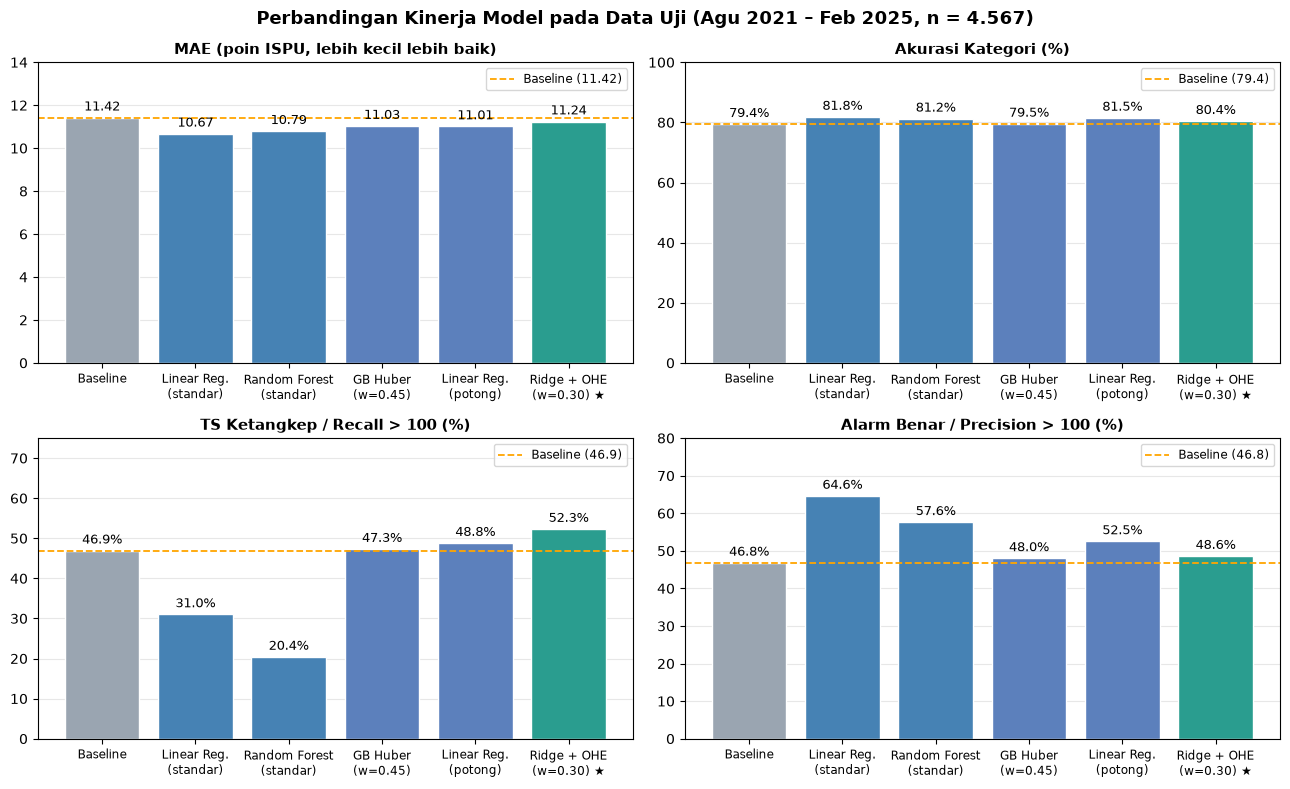

In [6]:
pilihan_grafik = [
    ("Baseline (besok = hari ini)", "Baseline"),
    ("Linear Regression", "Linear Reg.\n(standar)"),
    ("Random Forest", "Random Forest\n(standar)"),
    ("Gradient Boosting Huber (w_sedang=0.45)", "GB Huber\n(w=0.45)"),
    ("Linear Regression (Sedang dipotong)", "Linear Reg.\n(potong)"),
    ("Ridge + OHE bulan (w_sedang=0.30)", "Ridge + OHE\n(w=0.30) ★"),
]

sub_df = tabel_uji.set_index("model").loc[[p[0] for p in pilihan_grafik]].reset_index()
label_x = [p[1] for p in pilihan_grafik]
warna_bar = ["#9aa5b1", WARNA_UTAMA, WARNA_UTAMA, "#5c80bc", "#5c80bc", WARNA_TERPILIH]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
metrik_list = [
    ("MAE", "MAE (poin ISPU, lebih kecil lebih baik)", (0, 14), "%.2f"),
    ("akurasi_kategori_%", "Akurasi Kategori (%)", (0, 100), "%.1f%%"),
    ("TS_ketangkep_%", "TS Ketangkep / Recall > 100 (%)", (0, 75), "%.1f%%"),
    ("alarm_benar_%", "Alarm Benar / Precision > 100 (%)", (0, 80), "%.1f%%"),
]

for ax, (kol, judul, ylim, fmt) in zip(axes.flat, metrik_list):
    vals = sub_df[kol].values
    bars = ax.bar(label_x, vals, color=warna_bar, edgecolor="white")
    ax.axhline(vals[0], color=WARNA_BATAS, linestyle="--", linewidth=1.3, label=f"Baseline ({vals[0]})")
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9)
    ax.set_title(judul, fontsize=11, fontweight="bold")
    ax.set_ylim(*ylim)
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", labelsize=8.5)
    ax.legend(loc="upper right", fontsize=8.5)

fig.suptitle("Perbandingan Kinerja Model pada Data Uji (Agu 2021 – Feb 2025, n = 4.567)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FOLDER_GRAFIK / "7_perbandingan_model.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Confusion Matrix Kategori: Linear Regression Standar vs Model Terpilih

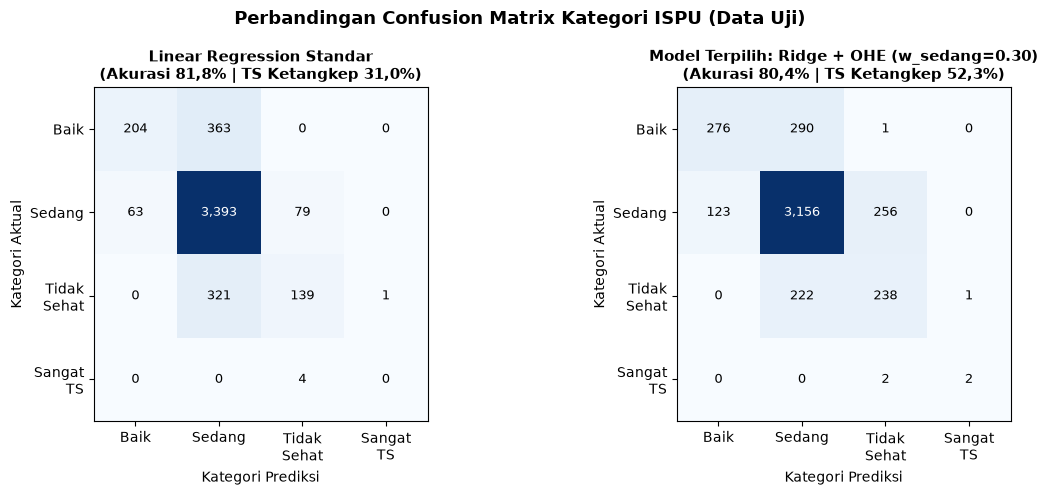

In [7]:
urutan_kat = ["BAIK", "SEDANG", "TIDAK SEHAT", "SANGAT TIDAK SEHAT"]
label_pendek = ["Baik", "Sedang", "Tidak\nSehat", "Sangat\nTS"]

kat_asli = y_uji.map(kategori_ispu)
kat_lr = pd.Series(prediksi_uji["Linear Regression"], index=y_uji.index).map(kategori_ispu)
kat_best = pd.Series(prediksi_uji["Ridge + OHE (w=0.30)"], index=y_uji.index).map(kategori_ispu)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (judul, kat_pred) in zip(axes, [
    ("Linear Regression Standar\n(Akurasi 81,8% | TS Ketangkep 31,0%)", kat_lr),
    ("Model Terpilih: Ridge + OHE (w_sedang=0.30)\n(Akurasi 80,4% | TS Ketangkep 52,3%)", kat_best),
]):
    cm = confusion_matrix(kat_asli, kat_pred, labels=urutan_kat)
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(urutan_kat)))
    ax.set_yticks(range(len(urutan_kat)))
    ax.set_xticklabels(label_pendek)
    ax.set_yticklabels(label_pendek)
    ax.set_xlabel("Kategori Prediksi")
    ax.set_ylabel("Kategori Aktual")
    ax.set_title(judul, fontsize=10.5, fontweight="bold")
    batas_gelap = cm.max() * 0.5
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            warna_teks = "white" if cm[i, j] > batas_gelap else "black"
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color=warna_teks, fontsize=9.5)

fig.suptitle("Perbandingan Confusion Matrix Kategori ISPU (Data Uji)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FOLDER_GRAFIK / "8_confusion_matrix_model.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Prediksi vs Aktual & Efek Musiman Model Terpilih

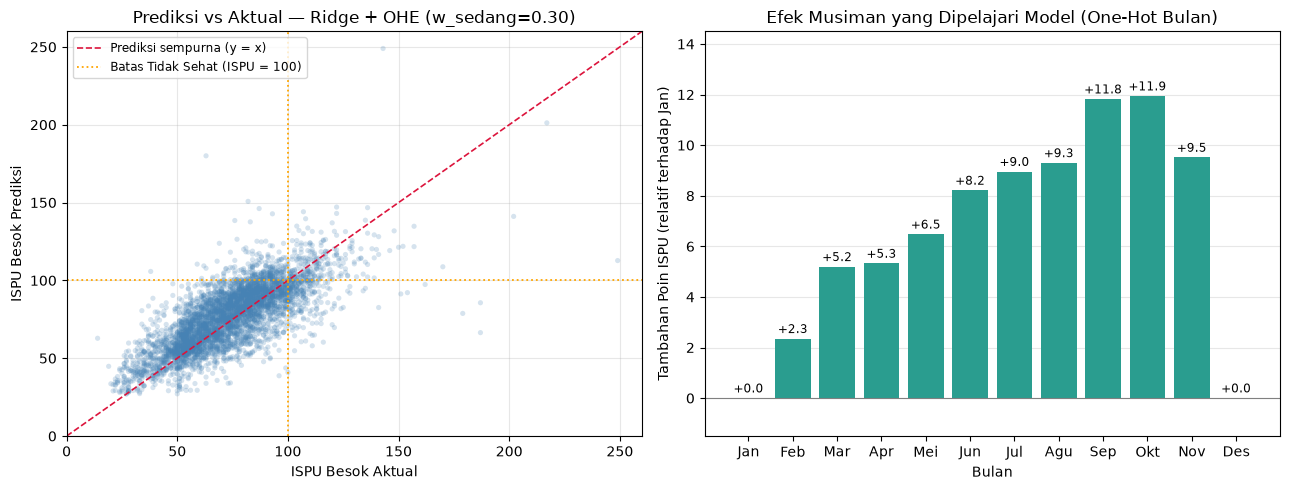

Koefisien fitur numerik:
  ispu_hari_ini  : +0.6190
  ispu_kemarin   : +0.2449
  hari           : -0.4806
  intercept      : +7.8216


In [8]:
model_terbaik = model_terlatih["Ridge + OHE (w=0.30)"]
pred_best = pd.Series(prediksi_uji["Ridge + OHE (w=0.30)"], index=y_uji.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel kiri: Prediksi vs Aktual
ax = axes[0]
ax.scatter(y_uji, pred_best, alpha=0.22, s=14, color=WARNA_UTAMA, edgecolors="none")
batas_plot = max(y_uji.max(), pred_best.max()) + 10
ax.plot([0, batas_plot], [0, batas_plot], color="crimson", linestyle="--", linewidth=1.2, label="Prediksi sempurna (y = x)")
ax.axvline(100, color=WARNA_BATAS, linestyle=":", linewidth=1.3, label="Batas Tidak Sehat (ISPU = 100)")
ax.axhline(100, color=WARNA_BATAS, linestyle=":", linewidth=1.3)
ax.set_xlim(0, 260)
ax.set_ylim(0, 260)
ax.set_xlabel("ISPU Besok Aktual")
ax.set_ylabel("ISPU Besok Prediksi")
ax.set_title("Prediksi vs Aktual — Ridge + OHE (w_sedang=0.30)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", fontsize=8.5)

# Panel kanan: Koefisien efek musiman per bulan (relatif terhadap Januari = 0)
ax = axes[1]
nama_fitur_out = model_terbaik.named_steps["prep"].get_feature_names_out()
koef = model_terbaik.named_steps["reg"].coef_
peta_koef = dict(zip(nama_fitur_out, koef))

bulan_label = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
efek_bulan = [0.0] + [peta_koef[f"bulan__bulan_{b}"] for b in range(2, 13)]
bars = ax.bar(bulan_label, efek_bulan, color=WARNA_TERPILIH)
ax.bar_label(bars, fmt="%+.1f", padding=2, fontsize=8.5)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Bulan")
ax.set_ylabel("Tambahan Poin ISPU (relatif terhadap Jan)")
ax.set_title("Efek Musiman yang Dipelajari Model (One-Hot Bulan)")
ax.set_ylim(-1.5, 14.5)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(FOLDER_GRAFIK / "9_prediksi_vs_aktual_dan_musiman.png", dpi=150, bbox_inches="tight")
plt.show()

print("Koefisien fitur numerik:")
for k in FITUR_LAIN:
    print(f"  {k:15s}: {peta_koef[f'num__{k}']:+.4f}")
print(f"  {'intercept':15s}: {model_terbaik.named_steps['reg'].intercept_:+.4f}")

### 5.4 Analisis Kesalahan, Kalibrasi Hari Tidak Sehat, dan Kinerja per Stasiun

In [9]:
asli_ts = y_uji > 100
pred_lr_s = pd.Series(prediksi_uji["Linear Regression"], index=y_uji.index)
lonjakan_mendadak = (asli_ts & (X_uji["ispu_hari_ini"] <= 100)).sum() / asli_ts.sum() * 100

print("=== Kalibrasi Hari Tidak Sehat (Data Uji) ===")
print(f"Proporsi hari Tidak Sehat aktual      : {asli_ts.mean() * 100:.1f}% ({asli_ts.sum()} dari {len(y_uji)} hari)")
print(f"Proporsi tebakan > 100 (LR standar)   : {(pred_lr_s > 100).mean() * 100:.1f}%")
print(f"Proporsi tebakan > 100 (Model terpilih): {(pred_best > 100).mean() * 100:.1f}%")
print(f"Rata-rata ISPU aktual saat TS         : {y_uji[asli_ts].mean():.1f}")
print(f"Rata-rata prediksi saat TS (LR std)   : {pred_lr_s[asli_ts].mean():.1f}")
print(f"Rata-rata prediksi saat TS (Terpilih) : {pred_best[asli_ts].mean():.1f}")
print(f"Hari TS yang datang setelah hari <=100: {lonjakan_mendadak:.1f}% (lonjakan mendadak)")

# Kinerja per stasiun pada data uji
df_eval_stasiun = uji[["stasiun", TARGET]].copy()
df_eval_stasiun["prediksi"] = pred_best.values

baris_stasiun = []
for st, grp in df_eval_stasiun.groupby("stasiun"):
    r = evaluasi(st, grp[TARGET], grp["prediksi"])
    baris_stasiun.append({
        "stasiun": st,
        "jumlah_uji": len(grp),
        "hari_TS_aktual": int((grp[TARGET] > 100).sum()),
        "MAE": r["MAE"],
        "akurasi_kategori_%": r["akurasi_kategori_%"],
        "TS_ketangkep_%": r["TS_ketangkep_%"],
        "alarm_benar_%": r["alarm_benar_%"],
    })

pd.DataFrame(baris_stasiun)

=== Kalibrasi Hari Tidak Sehat (Data Uji) ===
Proporsi hari Tidak Sehat aktual      : 10.2% (465 dari 4567 hari)
Proporsi tebakan > 100 (LR standar)   : 4.9%
Proporsi tebakan > 100 (Model terpilih): 10.9%
Rata-rata ISPU aktual saat TS         : 113.5
Rata-rata prediksi saat TS (LR std)   : 94.3
Rata-rata prediksi saat TS (Terpilih) : 101.5
Hari TS yang datang setelah hari <=100: 53.1% (lonjakan mendadak)


,stasiun,jumlah_uji,hari_TS_aktual,MAE,akurasi_kategori_%,TS_ketangkep_%,alarm_benar_%
0,DKI1 (Bunderan HI),903,32,10.17,79.5,18.8,14.6
1,DKI2 (Kelapa Gading),924,62,10.08,82.3,29.0,24.7
2,DKI3 (Jagakarsa),921,39,11.46,87.8,17.9,20.6
3,DKI4 (Lubang Buaya),897,249,13.33,77.7,71.1,67.8
4,DKI5 (Kebon Jeruk),922,83,11.21,74.6,42.2,38.5


## 6. Simpan Model Terbaik & Verifikasi Kontrak dengan Orang 3

Kontrak yang harus dipenuhi untuk aplikasi Streamlit (Orang 3):
1. Model disimpan di `MODEL_PATH` (`models/model.pkl`) dengan ukuran < 100 MB.
2. Model menerima DataFrame berkolom `FITUR` dalam urutan persis `config.py`.
3. Model mengeluarkan angka ISPU (konversi ke kategori dilakukan aplikasi via `kategori_ispu()`).

In [10]:
joblib.dump(model_terbaik, MODEL_PATH)
ukuran_mb = MODEL_PATH.stat().st_size / 1e6
print(f"Model tersimpan di: {MODEL_PATH}")
print(f"Ukuran file       : {ukuran_mb:.4f} MB ({MODEL_PATH.stat().st_size:,} bytes)")
assert ukuran_mb < 100, "Ukuran model melebihi batas 100 MB GitHub!"

# Verifikasi muat ulang & uji skenario input aplikasi (Orang 3)
model_cek = joblib.load(MODEL_PATH)
skenario = pd.DataFrame([
    [35, 30, 1, 6],    # Januari, Minggu, udara Baik
    [72, 68, 5, 2],    # Mei, Rabu, udara Sedang
    [98, 92, 10, 3],   # Oktober (puncak musim), Kamis, mendekati Tidak Sehat
    [125, 118, 10, 4], # Oktober, Jumat, Tidak Sehat
    [210, 195, 10, 0], # Oktober, Senin, Sangat Tidak Sehat
], columns=FITUR)

hasil_cek = model_cek.predict(skenario)
assert np.issubdtype(hasil_cek.dtype, np.floating), "Output model harus berupa angka!"

df_cek = skenario.copy()
df_cek["prediksi_ispu_besok"] = np.round(hasil_cek, 1)
df_cek["kategori_aplikasi"] = df_cek["prediksi_ispu_besok"].map(kategori_ispu)
df_cek

Model tersimpan di: D:\_SCHOOL\AI\AOL\prediksi-udara\models\model.pkl
Ukuran file       : 0.0033 MB (3,292 bytes)


,ispu_hari_ini,ispu_kemarin,bulan,hari,prediksi_ispu_besok,kategori_aplikasi
0,35,30,1,6,33.9,BAIK
1,72,68,5,2,74.6,SEDANG
2,98,92,10,3,101.5,TIDAK SEHAT
3,125,118,10,4,124.1,TIDAK SEHAT
4,210,195,10,0,197.5,TIDAK SEHAT
